In [1]:
import os
import pandas as pd
import librosa
import torch
import numpy as np
import matplotlib.pyplot as plt
from numpy import ndarray
import random
import glob
import matplotlib.pyplot as plt
from tqdm import tqdm

#from transformers import AutoProcessor, AutoModelForCTC
#from transformers import Wav2Vec2Processor, Wav2Vec2Model
import torch
import torchaudio

from scipy.stats import skew, kurtosis

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [2]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# F0 Inconsistency / Monotonic Speech (F0-based manipulation)

**Target system:** Concatenative TTS / some TTS that produce monotonic speech   
**Feature:** F0 trajectory    
**Manipulations:**
- F0 segment shifting  
- F0 segment shuffling
- F0 flattening


In [3]:
def load_audio(path, trim=True, normalize=True, sr=16000, top_db=40):
    
    waveform, sample_rate = librosa.load(path, sr=None, mono=True)
    waveform = torch.Tensor(waveform).unsqueeze(0)  # gotta fix torchaudio.load

    # Resample if necessary
    if sr != sample_rate:
        resampler = torchaudio.transforms.Resample(orig_freq=sample_rate, new_freq=sr)
        waveform = resampler(waveform)

    # Normalize waveform
    if normalize:
        peak = waveform.abs().max()
        if peak > 0:
            waveform = waveform / peak

    # Trim leading and trailing silence
    if trim:
        amplitude_threshold = 10 ** (-top_db / 20)
        non_silent = (waveform.abs() > amplitude_threshold).nonzero(as_tuple=True)[1]
        if non_silent.numel() > 0:
            start = non_silent[0].item()
            end = non_silent[-1].item() + 1
            waveform = waveform[:, start:end]
        else:
            waveform = waveform[:, :0]

    return waveform.squeeze()    

class STFTWindowParams:
    def __init__(self, sample_rate=16000, win_sec=0.032, hop_sec=0.016):
        self.sample_rate = sample_rate
        self.win_sec = win_sec
        self.hop_sec = hop_sec

        self.update()

    def update(self):
        self.win_size = int(self.win_sec * self.sample_rate)
        self.hop_size = int(self.hop_sec * self.sample_rate)
        self.fft_size = self.next_pow_2(self.win_size)

    @staticmethod
    def next_pow_2(x):
        return 2 ** (x - 1).bit_length()


def extract_f0(waveform,
              fs, win_size, hop_size,
              fmin: int = 70, fmax: int = 400) -> ndarray:

    x = np.copy(waveform)
    x = librosa.effects.preemphasis(x)
    autocorr_win_len = win_size // 2

    f0_freqs, _, _ = librosa.pyin(
        x, sr=fs,
        frame_length=win_size, hop_length=hop_size, center=True,
        win_length=autocorr_win_len, fmin=fmin, fmax=fmax, n_thresholds=7
    )

    return f0_freqs


def f0_segment_shift(f0_traj, seg_len_s, hop_s, p_seg):
    f0_mod = f0_traj.copy()
    voiced = ~np.isnan(f0_mod)

    seg_len_frames = int(seg_len_s / hop_s)
    i = 0

    while i < len(f0_mod):
        if not voiced[i]:
            i += 1
            continue

        # find voiced segment f0_mod[seg_start : seg_end]
        seg_start = i
        while i < len(f0_mod) and voiced[i]:
            i += 1
        seg_end = i

        # chunk the voiced segment in pseudo-phonemes, shift some
        j = seg_start
        while j < seg_end:
            seg_j_end = min(j + seg_len_frames, seg_end)

            if np.random.rand() < p_seg:
                shift = random.choice([
                    random.uniform(0.87, 0.92),
                    random.uniform(1.08, 1.3)
                ])
                f0_mod[j:seg_j_end] *= shift

            j = seg_j_end

    return f0_mod


def f0_segment_shuffle(f0_traj, seg_len_s, hop_s, p_shuffle):
    f0_mod = f0_traj.copy()
    voiced = ~np.isnan(f0_mod)

    seg_len_frames = int(seg_len_s / hop_s)

    segments = []
    indices = []

    i = 0
    while i < len(f0_mod):
        if not voiced[i]:
            i += 1
            continue
        
        # find voiced segment f0_mod[seg_start : seg_end]
        seg_start = i
        while i < len(f0_mod) and voiced[i]:
            i += 1
        seg_end = i

        # chunk the voiced segment in pseudo-phonemes    
        j = seg_start
        while j < seg_end:
            seg_j_end = min(j + seg_len_frames, seg_end)
            
            segments.append(f0_mod[j:seg_j_end].copy())
            indices.append((j, seg_j_end))
            j = seg_j_end

    if len(segments) < 2:
        return f0_mod

    # partial shuffle
    perm = list(range(len(segments)))
    for i in range(len(perm)):
        if random.random() < p_shuffle:
            j = random.randrange(len(perm))
            perm[i], perm[j] = perm[j], perm[i]
            
    # re-insert
    for out_i, src_i in enumerate(perm):
        start, end = indices[out_i]
        seg = segments[src_i]
        L = min(end - start, len(seg))
        f0_mod[start:start + L] = seg[:L]
    
    return f0_mod        


def flatten_f0(f0_traj, strength=0.9, p=0.5):

    f0_mod = f0_traj.copy()
    voiced = ~np.isnan(f0_mod)

    f0_ref = np.nanmedian(f0_mod)
    mask = (np.random.rand(len(f0_mod)) < p) & voiced

    f0_mod[mask] = (
        (1.0 - strength) * f0_mod[mask]
        + strength * f0_ref
    )

    return f0_mod


def apply_f0_mod(f0_traj, mod='shift', hop_s=0.016):
    
    if mod == 'shift':
        seg_len = random.uniform(0.08, 0.16)  # 80–160 ms
        p_seg = random.uniform(0.4, 0.7)

        f0_traj_mod = f0_segment_shift(
            f0_traj,
            seg_len_s=seg_len,
            hop_s=hop_s,
            p_seg=p_seg
        )
        
    elif mod == 'shuff':
        seg_len = random.uniform(0.08, 0.16)
        p_shuffle = random.uniform(0.2, 0.5)

        f0_traj_mod = f0_segment_shuffle(
            f0_traj,
            seg_len_s=seg_len,
            hop_s=hop_s,
            p_shuffle=p_shuffle
        )
        
    elif mod == 'flat':
        f0_traj_mod = flatten_f0(
            f0_traj,
            strength=0.5,
            p=1
        )
        
    else:
        f0_traj_mod = None
        print("Manipulation not recognized.")
        
    return f0_traj_mod


In [13]:
# ---------- corpus-level ----------
def corpus_f0_features(f0_list, hop_s):
    feats = []
    for f0 in f0_list:
        f = f0_concat_features(f0, hop_s)
        if f is not None:
            feats.append(f)
    return feats

def aggregate_features(feat_list):
    keys = feat_list[0].keys()
    agg = {}
    for k in keys:
        vals = np.array([f[k] for f in feat_list])
        agg[k + "_mean"] = np.mean(vals)
        agg[k + "_std"]  = np.std(vals)
    return agg

def compute_features_and_aggregate(df_real, df_fake, stft_params):
    
    # ---------- compute raw features ----------
    feat_nat  = corpus_f0_features(df_real['f0_traj'], stft_params.hop_sec)
    feat_man  = corpus_f0_features(df_real['f0_traj_mod'], stft_params.hop_sec)
    feat_fake = corpus_f0_features(df_fake['f0_traj'], stft_params.hop_sec)
    
    # ---------- compute globals ----------
    feat_nat_global  = aggregate_features(feat_nat)
    feat_man_global  = aggregate_features(feat_man)
    feat_fake_global = aggregate_features(feat_fake)

    return (
        feat_nat,
        feat_man,
        feat_fake,
        feat_nat_global,
        feat_man_global,
        feat_fake_global,
    )

def print_stats_and_plot(
    keys_to_plot,
    feat_nat,
    feat_man,
    feat_fake,
    feat_nat_global,
    feat_man_global,
    feat_fake_global,
):

    for k in keys_to_plot:

        print("=" * 60)
        print(k.upper())
        print()

        nat_mean = feat_nat_global[k + "_mean"]
        nat_std  = feat_nat_global[k + "_std"]

        man_mean = feat_man_global[k + "_mean"]
        man_std  = feat_man_global[k + "_std"]

        asv_mean = feat_fake_global[k + "_mean"]
        asv_std  = feat_fake_global[k + "_std"]

        # --- kurtosis ---
        #kurt_nat = kurtosis(np.array([f[k] for f in feat_nat]), fisher=True)
        #kurt_man = kurtosis(np.array([f[k] for f in feat_man]), fisher=True)
        #kurt_asv = kurtosis(np.array([f[k] for f in feat_fake]), fisher=True)

        print(f"Natural mean:       {nat_mean:.3f}")
        print(f"Natural std:        {nat_std:.3f}")
        #print(f"Natural kurtosis:   {kurt_nat:.3f}")
        print()

        print(f"Manipulated mean:   {man_mean:.3f}")
        print(f"Manipulated std:    {man_std:.3f}")
        #print(f"Manipulated kurtosis: {kurt_man:.3f}")
        print()

        print(f"ASV mean:           {asv_mean:.3f}")
        print(f"ASV std:            {asv_std:.3f}")
        #print(f"ASV kurtosis:       {kurt_asv:.3f}")
        print()

        # --- mean differences ---
        diff_nat_man = nat_mean - man_mean
        diff_nat_asv = nat_mean - asv_mean

        print(f"Nat - Manip (mean diff):  {diff_nat_man:.3f}")
        print(f"Nat - ASV (mean diff):    {diff_nat_asv:.3f}")
        print()

        # --- pooled std ---
        pooled_nat_man = np.sqrt((nat_std**2 + man_std**2) / 2)
        pooled_nat_asv = np.sqrt((nat_std**2 + asv_std**2) / 2)

        # --- effect sizes (Cohen's d) ---
        d_nat_man = diff_nat_man / pooled_nat_man
        d_nat_asv = diff_nat_asv / pooled_nat_asv

        print(f"Cohen's d (Nat vs Manip): {d_nat_man:.3f}")
        print(f"Cohen's d (Nat vs ASV):   {d_nat_asv:.3f}")
        print("=" * 60)
        print()

        # ---------- histogram ----------
        vals_nat  = np.array([f[k] for f in feat_nat])
        vals_man  = np.array([f[k] for f in feat_man])
        vals_fake = np.array([f[k] for f in feat_fake])

        plt.figure()

        plt.hist(
            vals_nat,
            bins=50,
            alpha=0.5,
            density=True,
            color="blue",
            label="Natural",
        )

        plt.hist(
            vals_man,
            bins=50,
            alpha=0.5,
            density=True,
            color="orange",
            label="Manipulated",
        )

        plt.hist(
            vals_fake,
            bins=50,
            alpha=0.5,
            density=True,
            color="red",
            label="ASV",
        )

        # mean lines
        plt.axvline(vals_nat.mean(),  color="blue",   linestyle="--")
        plt.axvline(vals_man.mean(),  color="orange", linestyle="--")
        plt.axvline(vals_fake.mean(), color="red",    linestyle="--")

        plt.title(f"{k} Distribution")
        plt.xlabel(k)
        plt.ylabel("Density")
        plt.legend()
        plt.show()


### Manipulation type and reference from ASVspoof2019:

In [5]:
mod = 'flat'

if mod == 'shift':
    algorithm = 'A04'  # ref for concat TTS
else:
    algorithm = 'A02'  # ref for flat pitch

### Load base tracks

### Extract F0 and apply manipulation


In [6]:
fs = 16000
stft_params = STFTWindowParams()

df_real = pd.read_pickle("pickles/F0_Inconsistency_DF_R.pkl")

nan_count = 0

for idx, row in tqdm(df_real.iterrows(), total=len(df_real)):
    f0_traj = row["f0_traj"]

    if np.all(np.isnan(f0_traj)):
        f0_traj_mod = None
        nan_count += 1
    else:
        f0_traj_mod = apply_f0_mod(
            f0_traj,
            mod=mod,
            hop_s=stft_params.hop_sec,
        )

    df_real.at[idx, "f0_traj_mod"] = f0_traj_mod

print(f"{nan_count}/{len(df_real)} tracks have all-NaN F0 trajectories")

df_real.to_pickle("pickles/F0_Inconsistency_DF_R.pkl")

df_real


100%|███████████████████████████████████████████████████████████████████| 2580/2580 [00:00<00:00, 4162.72it/s]


102/2580 tracks have all-NaN F0 trajectories


,name,f0_traj,f0_traj_mod
0,LA_T_1138215,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ..."
1,LA_T_1271820,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ..."
2,LA_T_1272637,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ..."
3,LA_T_1276960,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ..."
4,LA_T_1341447,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ..."
...,...,...,...
2575,LA_T_9387015,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ..."
2576,LA_T_9497115,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ..."
2577,LA_T_9557645,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ..."
2578,LA_T_9737995,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ..."


### Load Tracks from ASVspoof 2019

In [7]:
df_fake = pd.read_pickle(f"pickles/F0_Inconsistency_DF_F_{algorithm}.pkl")
df_fake

,name,f0_traj
0,LA_T_1025525,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ..."
1,LA_T_1090966,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ..."
2,LA_T_1148535,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ..."
3,LA_T_1191378,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ..."
4,LA_T_1278860,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ..."
...,...,...
3795,LA_T_9849084,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ..."
3796,LA_T_9866207,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ..."
3797,LA_T_9944104,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ..."
3798,LA_T_9954345,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ..."


### Compare using proxy scalar features distributions:
- Natural speech  
- Manipulated speech (our home-made modifications)  
- Speech from actual selected ASV19 generator 

In [8]:
# ---------- support functions ----------

def autocorr_decay(x, max_lag=50):
    x = x - np.mean(x)
    ac = np.correlate(x, x, mode="full")
    ac = ac[len(ac) // 2 :]
    ac /= ac[0] + 1e-8
    return np.mean(ac[1:max_lag])


def f0_concat_features(f0, hop_s):
    f0 = np.asarray(f0, dtype=float)

    voiced = ~np.isnan(f0)
    f0v = f0[voiced]

    if len(f0v) < 5:
        return None

    feats = {}

    # --- basic stats ---
    feats["f0_range"] = np.max(f0v) - np.min(f0v)
    feats["f0_var"] = np.var(f0v)
    feats["f0_std"] = np.std(f0v)
    feats["f0_ac_decay"] = autocorr_decay(f0v)

    feats["f0_skew"] = skew(f0v)
    feats["f0_kurtosis"] = kurtosis(f0v)

    # --- first derivative stats ---
    df0 = np.diff(f0v)

    feats["df0_std"] = np.std(df0)
    feats["df0_mean_abs"] = np.mean(np.abs(df0))
    feats["df0_max_abs"] = np.max(np.abs(df0))
    feats["df0_skew"] = skew(df0)

    return feats


F0_RANGE

Natural mean:       74.305
Natural std:        44.522

Manipulated mean:   37.153
Manipulated std:    22.261

ASV mean:           60.430
ASV std:            27.018

Nat - Manip (mean diff):  37.153
Nat - ASV (mean diff):    13.875

Cohen's d (Nat vs Manip): 1.056
Cohen's d (Nat vs ASV):   0.377



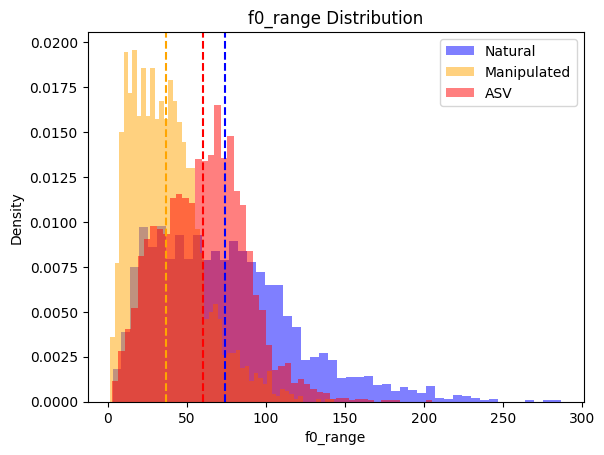

F0_VAR

Natural mean:       525.582
Natural std:        699.202

Manipulated mean:   131.395
Manipulated std:    174.800

ASV mean:           280.776
ASV std:            226.399

Nat - Manip (mean diff):  394.186
Nat - ASV (mean diff):    244.806

Cohen's d (Nat vs Manip): 0.773
Cohen's d (Nat vs ASV):   0.471



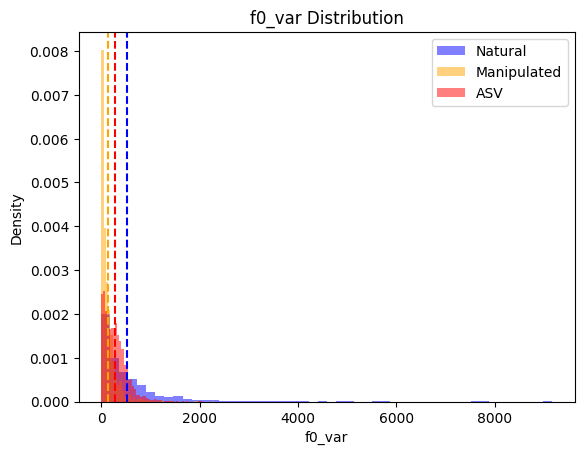

F0_STD

Natural mean:       19.426
Natural std:        12.174

Manipulated mean:   9.713
Manipulated std:    6.087

ASV mean:           15.356
ASV std:            6.705

Nat - Manip (mean diff):  9.713
Nat - ASV (mean diff):    4.070

Cohen's d (Nat vs Manip): 1.009
Cohen's d (Nat vs ASV):   0.414



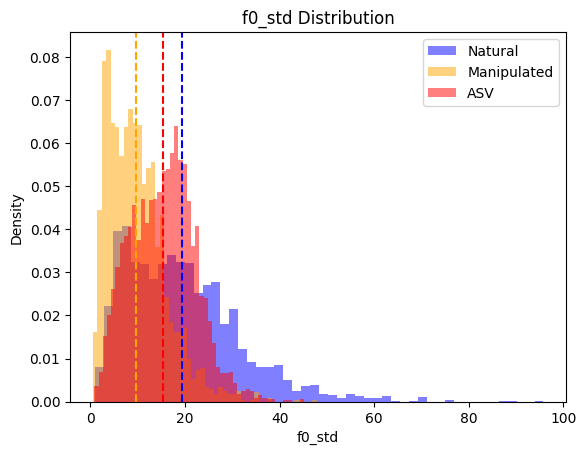

F0_AC_DECAY

Natural mean:       0.017
Natural std:        0.063

Manipulated mean:   0.017
Manipulated std:    0.063

ASV mean:           0.136
ASV std:            0.150

Nat - Manip (mean diff):  -0.000
Nat - ASV (mean diff):    -0.119

Cohen's d (Nat vs Manip): -0.000
Cohen's d (Nat vs ASV):   -1.033



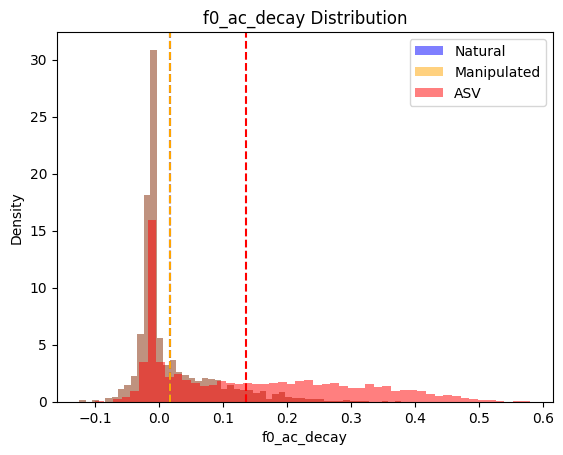

F0_SKEW

Natural mean:       0.274
Natural std:        0.779

Manipulated mean:   0.274
Manipulated std:    0.779

ASV mean:           -0.002
ASV std:            0.618

Nat - Manip (mean diff):  -0.000
Nat - ASV (mean diff):    0.276

Cohen's d (Nat vs Manip): -0.000
Cohen's d (Nat vs ASV):   0.392



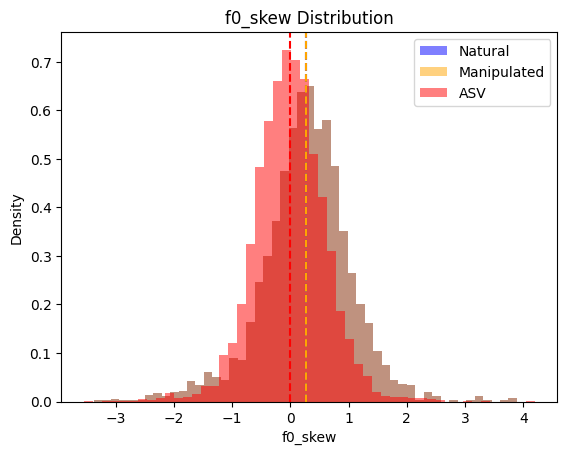

F0_KURTOSIS

Natural mean:       -0.034
Natural std:        1.804

Manipulated mean:   -0.034
Manipulated std:    1.804

ASV mean:           -0.383
ASV std:            1.312

Nat - Manip (mean diff):  -0.000
Nat - ASV (mean diff):    0.349

Cohen's d (Nat vs Manip): -0.000
Cohen's d (Nat vs ASV):   0.221



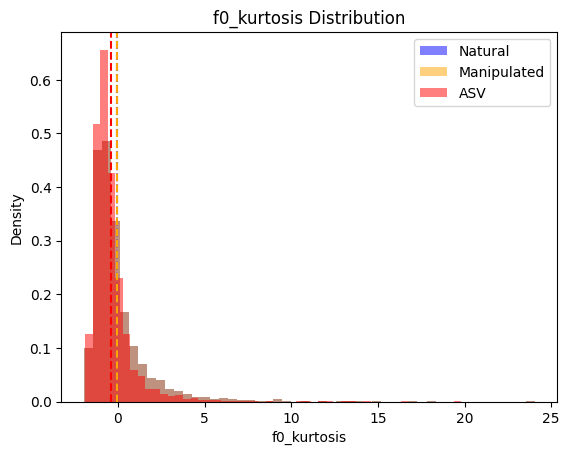

DF0_STD

Natural mean:       8.090
Natural std:        5.009

Manipulated mean:   4.045
Manipulated std:    2.504

ASV mean:           4.574
ASV std:            1.881

Nat - Manip (mean diff):  4.045
Nat - ASV (mean diff):    3.516

Cohen's d (Nat vs Manip): 1.021
Cohen's d (Nat vs ASV):   0.929



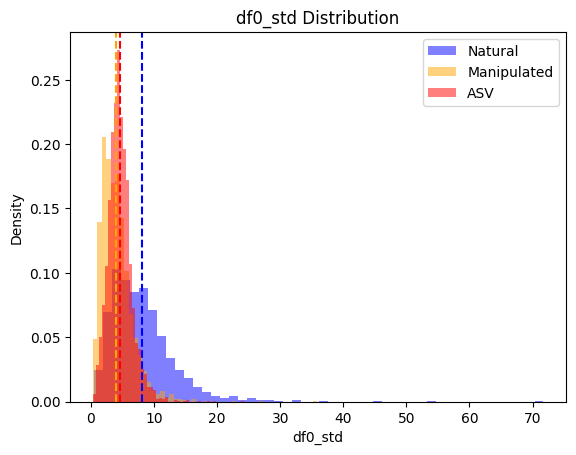

DF0_MEAN_ABS

Natural mean:       4.613
Natural std:        2.408

Manipulated mean:   2.307
Manipulated std:    1.204

ASV mean:           2.593
ASV std:            0.890

Nat - Manip (mean diff):  2.307
Nat - ASV (mean diff):    2.021

Cohen's d (Nat vs Manip): 1.212
Cohen's d (Nat vs ASV):   1.113



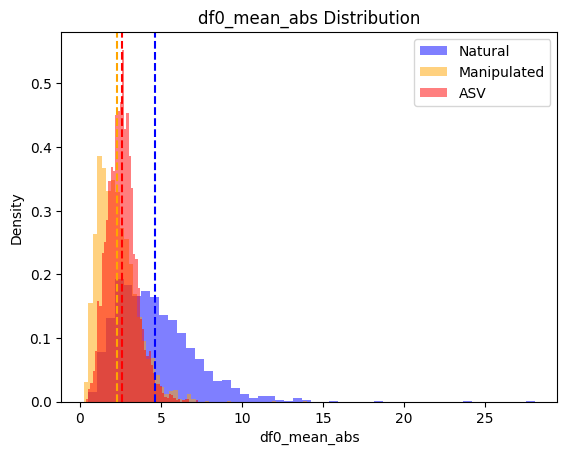

DF0_MAX_ABS

Natural mean:       35.699
Natural std:        27.448

Manipulated mean:   17.850
Manipulated std:    13.724

ASV mean:           22.594
ASV std:            11.782

Nat - Manip (mean diff):  17.850
Nat - ASV (mean diff):    13.105

Cohen's d (Nat vs Manip): 0.823
Cohen's d (Nat vs ASV):   0.620



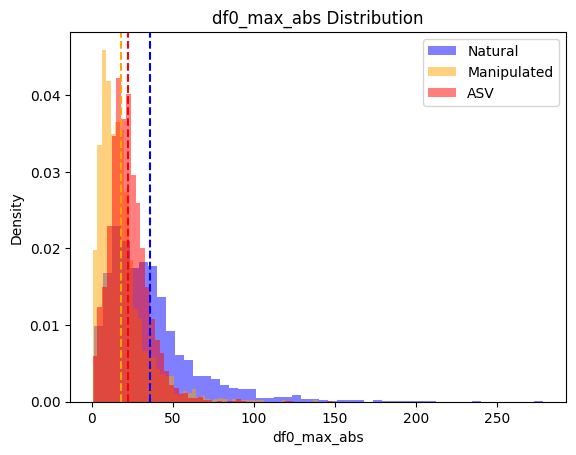

DF0_SKEW

Natural mean:       0.151
Natural std:        1.853

Manipulated mean:   0.151
Manipulated std:    1.853

ASV mean:           0.626
ASV std:            1.733

Nat - Manip (mean diff):  -0.000
Nat - ASV (mean diff):    -0.474

Cohen's d (Nat vs Manip): -0.000
Cohen's d (Nat vs ASV):   -0.264



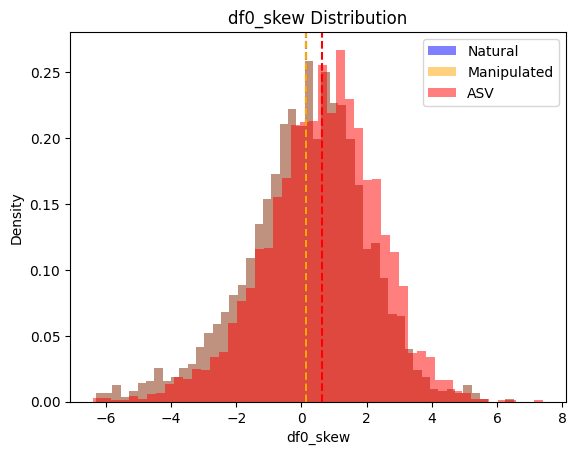

In [14]:
proxy_features_list = [
    "f0_range",
    "f0_var",
    "f0_std",
    "f0_ac_decay",
    "f0_skew",
    "f0_kurtosis",
    "df0_std",
    "df0_mean_abs",
    "df0_max_abs",
    "df0_skew",
]

feat_nat, feat_man, feat_fake, \
feat_nat_global, feat_man_global, feat_fake_global = compute_features_and_aggregate(
    df_real,
    df_fake,
    stft_params,
)

print_stats_and_plot(
    proxy_features_list,
    feat_nat,
    feat_man,
    feat_fake,
    feat_nat_global,
    feat_man_global,
    feat_fake_global,
)


## Inspect ASV19 TTS

In [10]:
def prepare_audio_window(x, max_len=48000, is_eval=True):
    x_len = x.shape[0]

    # --- repeat signal if too short ---
    while x_len < max_len:
        num_samples = min(x_len, max_len - x_len)
        x = torch.cat([x, x[:num_samples]], dim=0)
        x_len = x.shape[0]

    if not is_eval:
        # --- random crop (training mode) ---
        last_valid_start_sample = x_len - max_len

        if last_valid_start_sample != 0:
            start_sample = random.randrange(0, last_valid_start_sample)
        else:
            start_sample = 0

        x_pad = x[start_sample : start_sample + max_len]

    else:
        # --- deterministic middle crop (evaluation mode) ---
        num_windows = round(x_len / max_len)

        if num_windows % 2 == 1:  # odd number of windows
            middle = num_windows // 2
        else:  # even number of windows
            middle = (num_windows // 2) - 1

        start_sample = middle * max_len
        x_pad = x[start_sample : start_sample + max_len]

    return x_pad


In [11]:
p = "/Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_cm_protocols/ASVspoof2019.LA.cm.train.trn.txt"
f = "/Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_train/flac"

# p = "/Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_cm_protocols/ASVspoof2019.LA.cm.dev.trl.txt"
# f = "/Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_dev/flac"

# p = "/Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_cm_protocols/ASVspoof2019.LA.cm.eval.trl.txt"
# f = "/Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_eval/flac"

df_all = pd.read_csv(p, sep=" ", header=None)

In [12]:
df_target = (
    df_all[df_all[3] == f'{algorithm}']
    .assign(path=lambda df_all: df_all[1].apply(
        lambda x: os.path.join(f, f"{x}.flac")
    ))[['path']]
)

target_list = df_target['path'].tolist()
print(len(target_list))

3800


In [17]:
# ----- pick 5 random examples -----
sample_paths = random.sample(target_list, 5)


mel_transform = torchaudio.transforms.MelSpectrogram(
    sample_rate=16000,
    n_fft=1024,
    hop_length=256,
    n_mels=128
)

spec_transform = torchaudio.transforms.Spectrogram(
    n_fft=1024,
    hop_length=256,
    power=2
)

/tmp/ipykernel_3524498/3771159565.py:6: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y = torch.tensor(y)


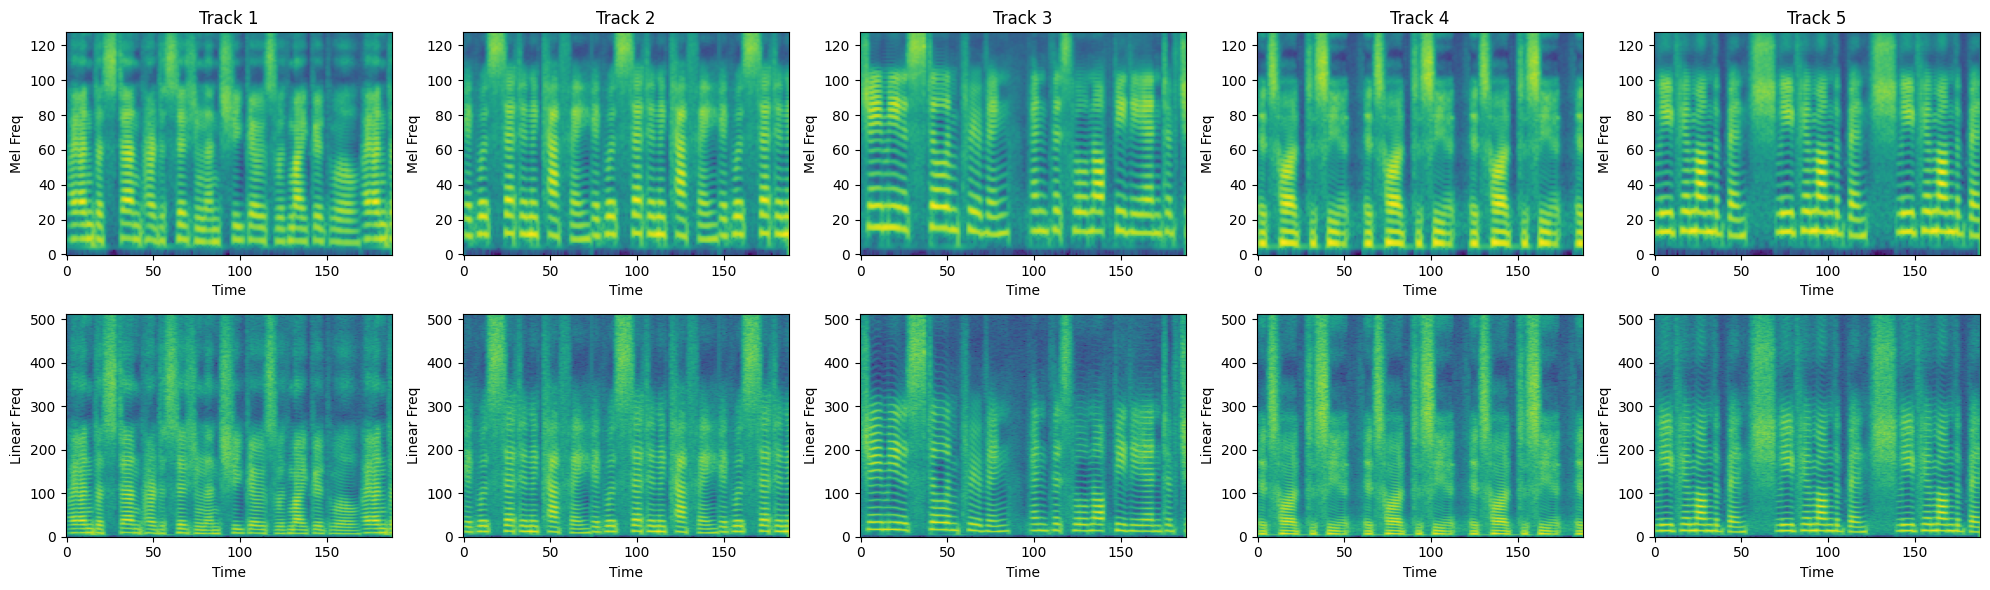

In [22]:
fig, axes = plt.subplots(2, 5, figsize=(20, 6))

for col, path in enumerate(sample_paths):

    y = load_audio(path, trim=True, normalize=True)
    y = torch.tensor(y)

    y = prepare_audio_window(y, is_eval=True)

    # add batch/channel dimension
    y = y.unsqueeze(0)

    # --- compute mel spectrogram ---
    mel_spec = mel_transform(y)
    mel_spec_db = torchaudio.functional.amplitude_to_DB(
        mel_spec,
        multiplier=10.0,
        amin=1e-10,
        db_multiplier=0
    )

    # --- compute linear spectrogram ---
    spec = spec_transform(y)
    spec_db = torchaudio.functional.amplitude_to_DB(
        spec,
        multiplier=10.0,
        amin=1e-10,
        db_multiplier=0
    )

    # remove batch dimension
    mel_img = mel_spec_db.squeeze().numpy()
    spec_img = spec_db.squeeze().numpy()

    # --- plot mel ---
    axes[0, col].imshow(mel_img, origin="lower", aspect="auto")
    axes[0, col].set_title(f"Track {col+1}")
    axes[0, col].set_xlabel("Time")
    axes[0, col].set_ylabel("Mel Freq")

    # --- plot linear ---
    axes[1, col].imshow(spec_img, origin="lower", aspect="auto")
    axes[1, col].set_xlabel("Time")
    axes[1, col].set_ylabel("Linear Freq")

plt.tight_layout()
plt.show()
